In [54]:
import pandas as PD
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np
Netflix = PD.read_csv('Netflix.csv', header=0 , sep=',')
train_set, test_set = train_test_split(Netflix,test_size=0.2, random_state = 42)
Netflix.shape

(5806, 15)

In [55]:
Netflix.head(3)

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts300399,Five Came Back: The Reference Films,SHOW,This collection includes 12 World War II-era p...,1945,TV-MA,48,['documentation'],['US'],1.0,NaN,NaN,NaN,0.600,NaN
1,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,113,"['crime', 'drama']",['US'],NaN,tt0075314,8.3,795222.0,27.612,8.2
2,tm127384,Monty Python and the Holy Grail,MOVIE,"King Arthur, accompanied by his squire, recrui...",1975,PG,91,"['comedy', 'fantasy']",['GB'],NaN,tt0071853,8.2,530877.0,18.216,7.8


In [56]:
Netflix.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5806 entries, 0 to 5805
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    5806 non-null   object 
 1   title                 5805 non-null   object 
 2   type                  5806 non-null   object 
 3   description           5788 non-null   object 
 4   release_year          5806 non-null   int64  
 5   age_certification     3196 non-null   object 
 6   runtime               5806 non-null   int64  
 7   genres                5806 non-null   object 
 8   production_countries  5806 non-null   object 
 9   seasons               2047 non-null   float64
 10  imdb_id               5362 non-null   object 
 11  imdb_score            5283 non-null   float64
 12  imdb_votes            5267 non-null   float64
 13  tmdb_popularity       5712 non-null   float64
 14  tmdb_score            5488 non-null   float64
dtypes: float64(5), int64(

In [57]:
Netflix['type'].unique()

array(['SHOW', 'MOVIE'], dtype=object)

In [58]:
Netflix['release_year'].unique()

array([1945, 1976, 1975, 1979, 1973, 1969, 1971, 1964, 1980, 1967, 1966,
       1961, 1954, 1958, 1968, 1977, 1972, 1963, 1960, 1956, 1953, 1974,
       1959, 1962, 1978, 1986, 1989, 1984, 1990, 1987, 1983, 1982, 1981,
       1988, 1985, 1995, 2000, 1997, 1994, 1996, 1999, 1998, 1993, 1992,
       1991, 2008, 2010, 2004, 2005, 2003, 2009, 2007, 2006, 2001, 2002,
       2012, 2011, 2014, 2013, 2015, 2016, 2017, 2018, 2019, 2020, 2022,
       2021], dtype=int64)

In [59]:
Netflix['age_certification'].unique()

array(['TV-MA', 'R', 'PG', 'TV-14', 'G', 'PG-13', nan, 'TV-PG', 'TV-Y',
       'TV-G', 'TV-Y7', 'NC-17'], dtype=object)

In [60]:
Netflix['genres'].unique()

array(["['documentation']", "['crime', 'drama']", "['comedy', 'fantasy']",
       ..., "['crime', 'comedy', 'drama', 'thriller', 'action']",
       "['music', 'romance', 'comedy']",
       "['family', 'comedy', 'animation']"], dtype=object)

In [62]:
Netflix['type'].value_counts()

type
MOVIE    3759
SHOW     2047
Name: count, dtype: int64

In [63]:
Netflix.describe()

,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,5806.000000,5806.000000,2047.000000,5283.000000,5.267000e+03,5712.000000,5488.000000
mean,2016.013434,77.643989,2.165608,6.533447,2.340719e+04,22.525660,6.818039
std,7.324883,39.474160,2.636207,1.160932,8.713432e+04,68.849177,1.171560
min,1945.000000,0.000000,1.000000,1.500000,5.000000e+00,0.009442,0.500000
25%,2015.000000,44.000000,1.000000,5.800000,5.210000e+02,3.155250,6.100000
50%,2018.000000,84.000000,1.000000,6.600000,2.279000e+03,7.478000,6.900000
75%,2020.000000,105.000000,2.000000,7.400000,1.014400e+04,17.775750,7.500000
max,2022.000000,251.000000,42.000000,9.600000,2.268288e+06,1823.374000,10.000000


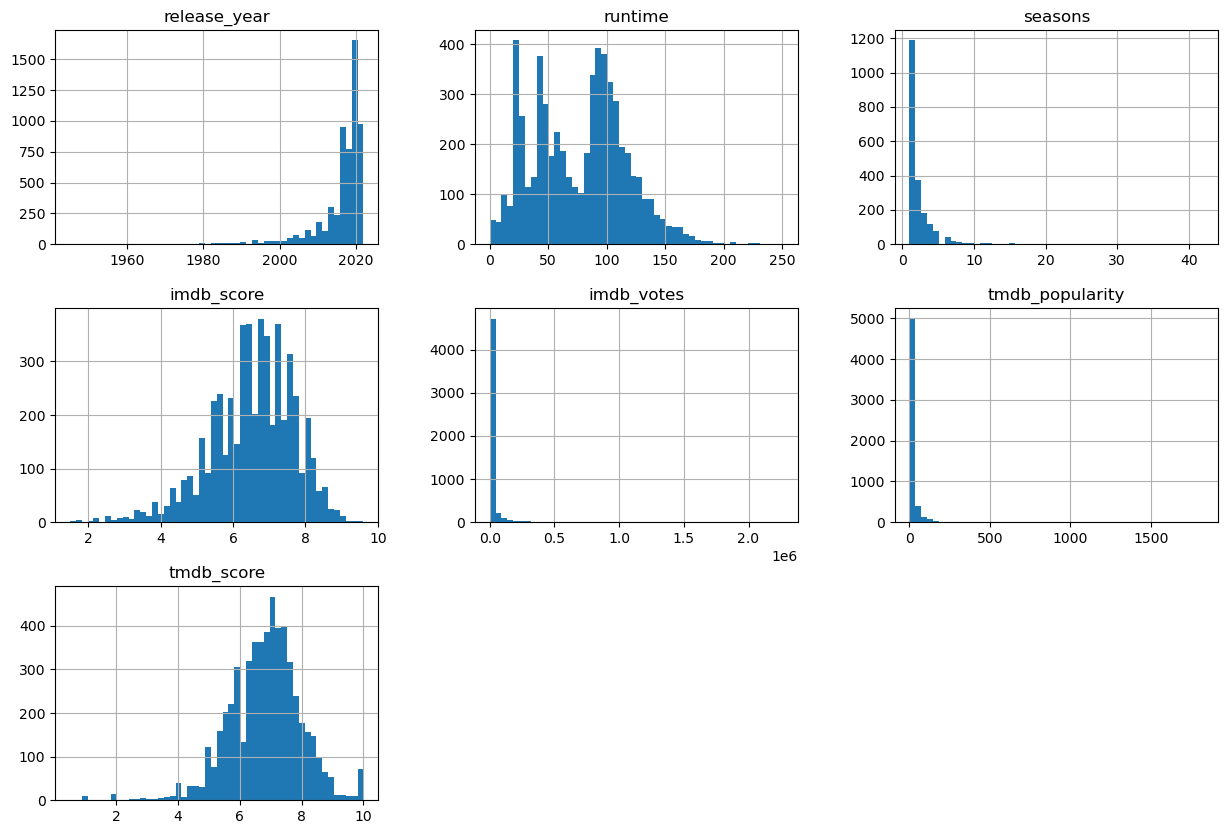

In [64]:
Netflix.hist(bins=50,figsize=(15,10))
plt.show()

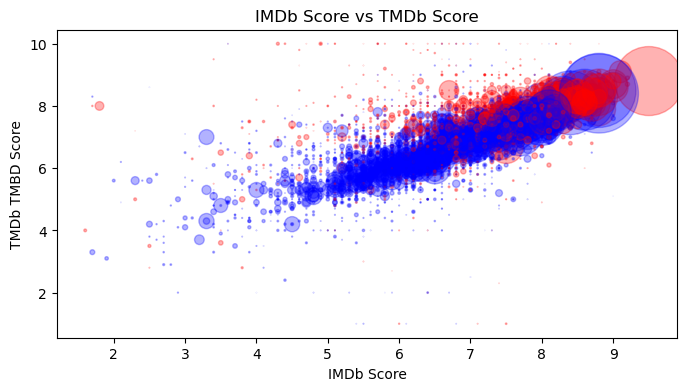

In [65]:
data=train_set.copy()
plt.figure(figsize=(8, 4))
plt.scatter(
    data["imdb_score"],
    data["tmdb_score"],
    s=data["imdb_votes"] / 700,
    c = ['red' if t == 'SHOW' else 'blue' for t in data["type"]],
    alpha=0.3
)
plt.xlabel("IMDb Score")
plt.ylabel("TMDb TMBD Score")
plt.title("IMDb Score vs TMDb Score")

plt.show()

In [66]:
corr_matrix = data.select_dtypes(include=["float64","int64"]).corr()
corr_matrix["imdb_score"].sort_values(ascending=False)

imdb_score         1.000000
tmdb_score         0.592409
imdb_votes         0.189443
seasons            0.082364
tmdb_popularity    0.017573
release_year      -0.102567
runtime           -0.150940
Name: imdb_score, dtype: float64

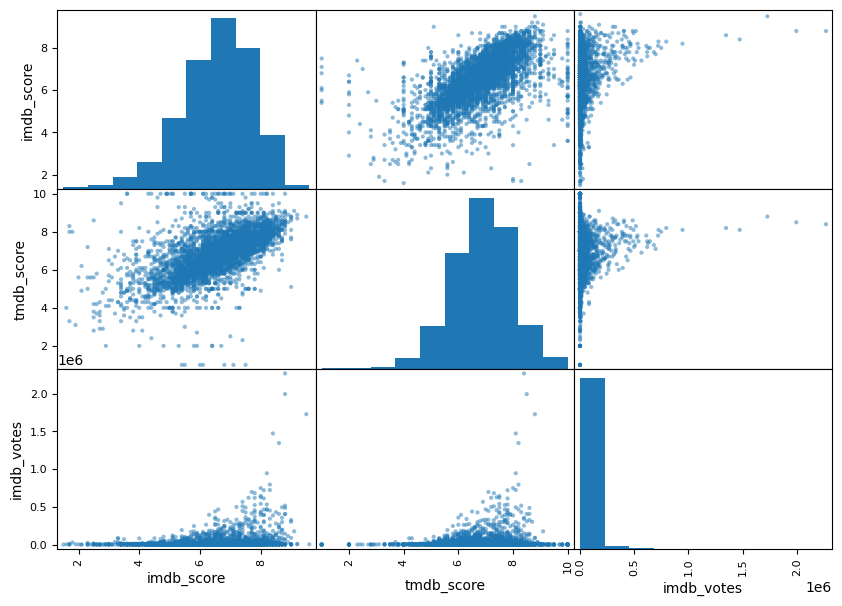

In [67]:
from pandas.plotting import scatter_matrix
features = ["imdb_score","tmdb_score","imdb_votes"]
scatter_matrix(data[features],figsize=(10,7))
plt.show()

In [68]:
data["imdb_votes_per_tmdb_score"] = data["imdb_votes"] / data["tmdb_score"]
data["tmdb_popularity_per_season"] = data["tmdb_popularity"] / data["seasons"]
data["imdb_votes_per_tmdb_popularity"] = data["imdb_votes"] / data["tmdb_popularity"]
corr_matrix = data.select_dtypes(include=["float64","int64"]).corr()
corr_matrix["imdb_score"].sort_values(ascending=False)

imdb_score                        1.000000
tmdb_score                        0.592409
imdb_votes                        0.189443
imdb_votes_per_tmdb_score         0.178593
imdb_votes_per_tmdb_popularity    0.102573
seasons                           0.082364
tmdb_popularity_per_season        0.065244
tmdb_popularity                   0.017573
release_year                     -0.102567
runtime                          -0.150940
Name: imdb_score, dtype: float64

In [69]:
df = train_set.copy()
df = df.dropna(subset=["imdb_score"])
df_label = df["imdb_score"].copy()
df = df.drop("imdb_score",axis=1)
df = df.drop("id",axis=1)
df = df.drop("description",axis=1)
df = df.drop("imdb_id",axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4246 entries, 4900 to 860
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   title                 4246 non-null   object 
 1   type                  4246 non-null   object 
 2   release_year          4246 non-null   int64  
 3   age_certification     2402 non-null   object 
 4   runtime               4246 non-null   int64  
 5   genres                4246 non-null   object 
 6   production_countries  4246 non-null   object 
 7   seasons               1515 non-null   float64
 8   imdb_votes            4236 non-null   float64
 9   tmdb_popularity       4183 non-null   float64
 10  tmdb_score            4065 non-null   float64
dtypes: float64(4), int64(2), object(5)
memory usage: 398.1+ KB


In [70]:
df_num = df.drop("title",axis=1)
df_num = df_num.drop("type",axis=1)
df_num = df_num.drop("age_certification",axis=1)
df_num = df_num.drop("genres",axis=1)
df_num = df_num.drop("production_countries",axis=1)
df_num.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4246 entries, 4900 to 860
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   release_year     4246 non-null   int64  
 1   runtime          4246 non-null   int64  
 2   seasons          1515 non-null   float64
 3   imdb_votes       4236 non-null   float64
 4   tmdb_popularity  4183 non-null   float64
 5   tmdb_score       4065 non-null   float64
dtypes: float64(4), int64(2)
memory usage: 232.2 KB


In [71]:
#median = df_num["release_year"].median()
#df_num["release_year"].fillna(median)
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values = np.nan,strategy='median')
imputer.fit(df_num)
X = imputer.transform(df_num)
df_num_T = PD.DataFrame(X, columns=df_num.columns)
df_num_T.info()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4246 entries, 0 to 4245
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   release_year     4246 non-null   float64
 1   runtime          4246 non-null   float64
 2   seasons          4246 non-null   float64
 3   imdb_votes       4246 non-null   float64
 4   tmdb_popularity  4246 non-null   float64
 5   tmdb_score       4246 non-null   float64
dtypes: float64(6)
memory usage: 199.2 KB
<class 'pandas.core.frame.DataFrame'>
Index: 4246 entries, 4900 to 860
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   title                 4246 non-null   object 
 1   type                  4246 non-null   object 
 2   release_year          4246 non-null   int64  
 3   age_certification     2402 non-null   object 
 4   runtime               4246 non-null   int64  
 5   genres            

In [72]:
from sklearn.base import BaseEstimator, TransformerMixin
imdb_votes_ix , tmdb_score_ix , tmdb_popularity_ix , seasons_ix = 3,5,4,2
class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def fit(self,X,y=None): 
        return self
    def transform(self,X,y=None):
       imdb_votes_per_tmdb_score = X[:,imdb_votes_ix] / X[:,tmdb_score_ix]
       tmdb_popularity_per_season = X[:,tmdb_popularity_ix] / X[:,seasons_ix]
       imdb_votes_per_tmdb_popularity = X[:,imdb_votes_ix] / X[:,tmdb_popularity_ix]
       return np.c_[X,imdb_votes_per_tmdb_score,tmdb_popularity_per_season,imdb_votes_per_tmdb_popularity]
custom = CombinedAttributesAdder()
data_custom_T_tmp = custom.transform(df_num_T.values)
data_custom_T = PD.DataFrame(data_custom_T_tmp)
columns = list(df_num_T.columns)
columns.append("imdb_votes_per_tmdb_score")
columns.append("tmdb_popularity_per_season")
columns.append("imdb_votes_per_tmdb_popularity")
data_custom_T.columns = columns
data_custom_T.head(10)

,release_year,runtime,seasons,imdb_votes,tmdb_popularity,tmdb_score,imdb_votes_per_tmdb_score,tmdb_popularity_per_season,imdb_votes_per_tmdb_popularity
0,2022.0,119.0,1.0,1768.0,255.762,5.6,315.714286,255.76200,6.912677
1,2019.0,52.0,4.0,251168.0,309.755,8.4,29900.952381,77.43875,810.860196
2,2020.0,43.0,1.0,291.0,6.128,6.8,42.794118,6.12800,47.486945
3,2020.0,49.0,1.0,2759.0,10.962,7.0,394.142857,10.96200,251.687648
4,2019.0,128.0,1.0,859.0,1.632,5.0,171.800000,1.63200,526.348039
5,2021.0,153.0,1.0,30439.0,5.557,5.8,5248.103448,5.55700,5477.595825
6,2021.0,70.0,1.0,281.0,2.859,5.0,56.200000,2.85900,98.286114
7,1992.0,171.0,1.0,6199.0,5.065,6.6,939.242424,5.06500,1223.889437
8,2001.0,87.0,1.0,91584.0,21.013,6.1,15013.770492,21.01300,4358.444772
9,2011.0,96.0,1.0,4118.0,1.776,6.3,653.650794,1.77600,2318.693694


In [73]:
from sklearn.preprocessing import StandardScaler

feature_scal = StandardScaler()
data_num_scaled_T = PD.DataFrame(feature_scal.fit_transform(data_custom_T.values),columns=data_custom_T.columns)
data_num_scaled_T.head()

,release_year,runtime,seasons,imdb_votes,tmdb_popularity,tmdb_score,imdb_votes_per_tmdb_score,tmdb_popularity_per_season,imdb_votes_per_tmdb_popularity
0,0.833388,1.017444,-0.252537,-0.241664,3.172052,-1.065552,-0.257761,4.065796,-0.206020
1,0.419923,-0.701460,1.469526,2.494880,3.910026,1.394423,2.278810,1.009754,-0.061114
2,0.557745,-0.932357,-0.252537,-0.257870,-0.239935,-0.011277,-0.281160,-0.212345,-0.198707
3,0.557745,-0.778426,-0.252537,-0.230790,-0.173865,0.164436,-0.251036,-0.129501,-0.161901
4,0.419923,1.248341,-0.252537,-0.251638,-0.301387,-1.592690,-0.270099,-0.289396,-0.112395


In [74]:
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
import ast

df['type_'] = df['type'].fillna('missing')
encoder_type = OneHotEncoder(sparse_output=False)
type_1hot_tmp = encoder_type.fit_transform(df[['type_']])
type_1hot = PD.DataFrame(type_1hot_tmp, 
                         columns=encoder_type.get_feature_names_out(['type_']),
                         index=df.index)

type_1hot = type_1hot.drop(columns=[col for col in type_1hot.columns if 'missing' in col])

df['age_'] = df['age_certification'].fillna('missing') 
encoder_age = OneHotEncoder(sparse_output=False)
age_1hot_tmp = encoder_age.fit_transform(df[['age_']])
age_1hot = PD.DataFrame(age_1hot_tmp, 
                         columns=encoder_age.get_feature_names_out(['age_']),
                         index=df.index)

age_1hot = age_1hot.drop(columns=[col for col in age_1hot.columns if 'missing' in col])
def safe_eval(x):
    try:
        return ast.literal_eval(x) if isinstance(x, str) else x
    except:
        return []

df['genres'] = df['genres'].apply(safe_eval)

mlb = MultiLabelBinarizer()
genres_encoded = mlb.fit_transform(df['genres'])
genres_df = PD.DataFrame(genres_encoded, columns=mlb.classes_, index=df.index)

data_num_scaled_T.index = df.index
final = PD.concat([data_num_scaled_T,type_1hot,age_1hot,genres_df], axis=1)

final.head(3)

,release_year,runtime,seasons,imdb_votes,tmdb_popularity,tmdb_score,imdb_votes_per_tmdb_score,tmdb_popularity_per_season,imdb_votes_per_tmdb_popularity,type__MOVIE,...,history,horror,music,reality,romance,scifi,sport,thriller,war,western
4900,0.833388,1.017444,-0.252537,-0.241664,3.172052,-1.065552,-0.257761,4.065796,-0.206020,1.0,...,0,0,0,0,0,0,0,0,0,0
3182,0.419923,-0.701460,1.469526,2.494880,3.910026,1.394423,2.278810,1.009754,-0.061114,0.0,...,0,0,0,0,0,0,0,0,0,0
4763,0.557745,-0.932357,-0.252537,-0.257870,-0.239935,-0.011277,-0.281160,-0.212345,-0.198707,0.0,...,0,0,0,1,0,0,0,0,0,0


In [75]:
import ast
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer
from sklearn.impute import SimpleImputer

class DataFrameSelector(BaseEstimator, TransformerMixin):
    def __init__(self, attribute_names):
        self.attribute_names = attribute_names
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.attribute_names].values

imdb_votes_ix , tmdb_score_ix , tmdb_popularity_ix , seasons_ix = 3,5,4,2
class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): 
        return self
    def transform(self, X, y=None):
        imdb_votes_per_tmdb_score = X[:, imdb_votes_ix] / X[:, tmdb_score_ix]
        tmdb_popularity_per_season = X[:, tmdb_popularity_ix] / X[:, seasons_ix]
        imdb_votes_per_tmdb_popularity = X[:, imdb_votes_ix] / X[:, tmdb_popularity_ix]
        return np.c_[X, imdb_votes_per_tmdb_score, tmdb_popularity_per_season, imdb_votes_per_tmdb_popularity]

class GenresTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        if not isinstance(X, PD.Series):
            X = PD.Series(X.flatten())
        def safe_eval(x):
            try:
                return ast.literal_eval(x) if isinstance(x, str) else x
            except:
                return []
        genres_parsed = X.apply(safe_eval)
        self.mlb = MultiLabelBinarizer()
        self.mlb.fit(genres_parsed)
        return self

    def transform(self, X):
        if not isinstance(X, PD.Series):
            X = PD.Series(X.flatten())
        def safe_eval(x):
            try:
                return ast.literal_eval(x) if isinstance(x, str) else x
            except:
                return []
        genres_parsed = X.apply(safe_eval)
        genres_encoded = self.mlb.transform(genres_parsed)
        return genres_encoded

    def get_feature_names_out(self, input_features=None):
        return list(self.mlb.classes_)

df = train_set.copy()

df = df.dropna(subset=["imdb_score"])
df_label = df["imdb_score"].copy()
df = df.drop(["imdb_score", "id", "description", "imdb_id", "production_countries"], axis=1)
num_attrs = df.drop(["title", "type", "age_certification", "genres"], axis=1).columns.tolist()
cat_type_attrs = ['type']
cat_age_attrs = ['age_certification']
genres_attr = ['genres']

num_pipeline = Pipeline([
    ('selector', DataFrameSelector(num_attrs)),
    ('imputer', SimpleImputer(strategy='median')),
    ('attribs_adder', CombinedAttributesAdder()),
    ('std_scaler', StandardScaler()),
])

type_pipeline = Pipeline([
    ('selector', DataFrameSelector(cat_type_attrs)),
    ('fill_missing', SimpleImputer(strategy='constant', fill_value='missing')),
    ('one_hot', OneHotEncoder(sparse_output=False)),
])

age_pipeline = Pipeline([
    ('selector', DataFrameSelector(cat_age_attrs)),
    ('fill_missing', SimpleImputer(strategy='constant', fill_value='missing')),
    ('one_hot', OneHotEncoder(sparse_output=False)),
])

genres_pipeline = Pipeline([
    ('selector', DataFrameSelector(genres_attr)),
    ('genres_transform', GenresTransformer()),
])

full_pipeline = FeatureUnion(transformer_list=[
    ("num_pipeline", num_pipeline),
    ("type_pipeline", type_pipeline),
    ("age_pipeline", age_pipeline),
    ("genres_pipeline", genres_pipeline),
])

Netflix_prepared = full_pipeline.fit_transform(df)

num_features = num_attrs + [
    "imdb_votes_per_tmdb_score",
    "tmdb_popularity_per_season",
    "imdb_votes_per_tmdb_popularity"
]
type_features = full_pipeline.transformer_list[1][1].named_steps['one_hot'].get_feature_names_out(['type'])
age_features = full_pipeline.transformer_list[2][1].named_steps['one_hot'].get_feature_names_out(['age_certification'])
genres_features = full_pipeline.transformer_list[3][1].named_steps['genres_transform'].get_feature_names_out()

feature_names = np.concatenate([num_features, type_features, age_features, genres_features])

final_df = PD.DataFrame(Netflix_prepared, columns=feature_names, index=df.index)
final_df.head()

,release_year,runtime,seasons,imdb_votes,tmdb_popularity,tmdb_score,imdb_votes_per_tmdb_score,tmdb_popularity_per_season,imdb_votes_per_tmdb_popularity,type_MOVIE,...,history,horror,music,reality,romance,scifi,sport,thriller,war,western
4900,0.833388,1.017444,-0.252537,-0.241664,3.172052,-1.065552,-0.257761,4.065796,-0.206020,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3182,0.419923,-0.701460,1.469526,2.494880,3.910026,1.394423,2.278810,1.009754,-0.061114,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4763,0.557745,-0.932357,-0.252537,-0.257870,-0.239935,-0.011277,-0.281160,-0.212345,-0.198707,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3893,0.557745,-0.778426,-0.252537,-0.230790,-0.173865,0.164436,-0.251036,-0.129501,-0.161901,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4695,0.419923,1.248341,-0.252537,-0.251638,-0.301387,-1.592690,-0.270099,-0.289396,-0.112395,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [76]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(final_df,df_label)
sample_data_prepared = final_df.iloc[:4]
print("predict:::\t",lin_reg.predict(sample_data_prepared))

sample_labels = df_label.iloc[:4]
print("labels:::\t",list(sample_labels))

predict:::	 [5.57152911 8.07045682 5.3605058  7.28076458]
labels:::	 [5.7, 8.3, 5.8, 6.3]


In [77]:
from sklearn.metrics import mean_squared_error

Netflix_Predictions = lin_reg.predict(final_df)
lin_mse = mean_squared_error(df_label, Netflix_Predictions)
lin_rmse = np.sqrt(lin_mse)
lin_rmse

0.8641062206428222

In [78]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = DecisionTreeRegressor()
tree_reg.fit(final_df,df_label)
Netflix_Predictions = tree_reg.predict(final_df)
tree_mse = mean_squared_error(df_label, Netflix_Predictions)
tree_rmse = np.sqrt(tree_mse)
tree_rmse

1.0290764738421967e-16

In [79]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(tree_reg, final_df, df_label, scoring="neg_mean_squared_error", cv=10)
trees_rmse_scores = np.sqrt(-scores)
def display_scores(scores, model_name):
   print("--------" , model_name , "--------")
   print("Scores:::",scores)
   print("Mean:::",scores.mean())
   print("Standard deviation:::", scores.std())
    
display_scores(trees_rmse_scores,"Decision Tree Regression")

-------- Decision Tree Regression --------
Scores::: [1.05604144 1.0348174  1.12483201 1.05698795 1.04861814 1.1158115
 1.08090196 1.05364372 1.11718987 1.14835814]
Mean::: 1.0837202142532747
Standard deviation::: 0.03746360415323845


In [80]:
linear_scores = cross_val_score(lin_reg,final_df, df_label, scoring="neg_mean_squared_error", cv=10)
linear_rmse_scores = np.sqrt(-linear_scores)
display_scores(linear_rmse_scores,"Linear Regression")

-------- Linear Regression --------
Scores::: [1.11277468 0.83462191 0.93557121 0.90570514 0.86369585 0.87093021
 0.85099319 0.82638675 0.81541761 0.96937691]
Mean::: 0.8985473476475054
Standard deviation::: 0.08530830833579466


In [81]:
from sklearn.ensemble  import RandomForestRegressor

forest_reg = RandomForestRegressor()
forest_reg.fit(final_df,df_label)
forest_scores = cross_val_score(forest_reg, final_df, df_label, scoring="neg_mean_squared_error", cv=10)
forest_rmse_scores = np.sqrt(-forest_scores)
display_scores(forest_rmse_scores, "Random Forest regression")

-------- Random Forest regression --------
Scores::: [0.74955459 0.7311176  0.81309041 0.82131968 0.7732077  0.77688077
 0.77804694 0.76329228 0.76899859 0.90635502]
Mean::: 0.7881863570924967
Standard deviation::: 0.04676963818512339


In [82]:
from sklearn.ensemble  import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
param_grid = [{'n_estimators' : [3,4,6,10,30],'max_features' : [2,6,8,15]}]
forest_reg = RandomForestRegressor()

grid_search = GridSearchCV(forest_reg, param_grid, cv=5, scoring="neg_mean_squared_error")
grid_search.fit(final_df,df_label)

print("best parameters:",grid_search.best_params_)
print("best estimator:",grid_search.best_estimator_)

best parameters: {'max_features': 15, 'n_estimators': 30}
best estimator: RandomForestRegressor(max_features=15, n_estimators=30)


In [84]:
from sklearn.metrics import mean_squared_error

final_model = grid_search.best_estimator_
test_set = test_set.dropna(subset=["imdb_score"])
X = test_set.drop("imdb_score",axis=1)
Y = test_set["imdb_score"].copy()
X_prepared = full_pipeline.transform(X)
X_prepared_df = PD.DataFrame(X_prepared, columns=final_df.columns, index=X.index)
final_predictions = final_model.predict(X_prepared_df)
final_mse = mean_squared_error(Y, final_predictions)
final_rmse = np.sqrt(final_mse)
final_rmse

0.7599338058435763